mount drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Pretrained model for positive negative

In [ ]:
# =====================================================
# STEP 1: Install dependencies
# =====================================================
!pip install transformers datasets torch --quiet

# =====================================================
# STEP 2: Import libraries
# =====================================================
from transformers import pipeline
import pandas as pd

# =====================================================
# STEP 3: Load Pretrained Sentiment Model
# =====================================================
# DistilBERT fine-tuned on SST-2 (binary sentiment)
classifier = pipeline("sentiment-analysis",
                      model="distilbert-base-uncased-finetuned-sst-2-english")

# =====================================================
# STEP 4: Test the model on sample text
# =====================================================
examples = [
    "I love this product, it works great!",
    "This is the worst experience I’ve ever had.",
    "Absolutely fantastic customer service!",
    "Not good, I will never buy again."
]

for text in examples:
    result = classifier(text)[0]
    print(f"Text: {text}\nPrediction: {result['label']} (score: {result['score']:.4f})\n")

# =====================================================
# STEP 5: (Optional) Run on your own dataset (CSV)
# =====================================================
# Suppose you upload a CSV with a column called 'comment'
# Uncomment the next lines after uploading your file in Colab

# from google.colab import files
# uploaded = files.upload()   # Upload your CSV file

# df = pd.read_csv("your_file.csv")   # Replace with actual filename
# df['prediction'] = df['comment'].apply(lambda x: classifier(x)[0]['label'])
# df['score'] = df['comment'].apply(lambda x: classifier(x)[0]['score'])

# Save results
# df.to_csv("sentiment_results.csv", index=False)
# print("Predictions saved to sentiment_results.csv")


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

Device set to use cpu


Text: I love this product, it works great!
Prediction: POSITIVE (score: 0.9999)

Text: This is the worst experience I’ve ever had.
Prediction: NEGATIVE (score: 0.9998)

Text: Absolutely fantastic customer service!
Prediction: POSITIVE (score: 0.9999)

Text: Not good, I will never buy again.
Prediction: NEGATIVE (score: 0.9994)



pretrained model for categorization

In [ ]:
!pip install transformers --quiet

from transformers import pipeline

# Load zero-shot classification pipeline
classifier = pipeline("zero-shot-classification",
                      model="facebook/bart-large-mnli")

# Example comments
comments = [
    "The product broke after one use, terrible quality!",
    "Customer service was rude and unhelpful.",
    "The delivery was delayed by two weeks.",
    "Way too expensive for what it offers."
]

# Define categories
labels = ["service issue", "product quality issue", "delivery issue", "pricing issue"]

# Classify each comment
for comment in comments:
    result = classifier(comment, candidate_labels=labels)
    print(f"\nComment: {comment}")
    print("Predicted Category:", result["labels"][0], " (score:", result["scores"][0], ")")


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.63G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cpu



Comment: The product broke after one use, terrible quality!
Predicted Category: product quality issue  (score: 0.9125757813453674 )

Comment: Customer service was rude and unhelpful.
Predicted Category: service issue  (score: 0.9870796799659729 )

Comment: The delivery was delayed by two weeks.
Predicted Category: delivery issue  (score: 0.7899682521820068 )

Comment: Way too expensive for what it offers.
Predicted Category: pricing issue  (score: 0.8964870572090149 )


dataset download

In [ ]:
!pip install kagglehub --quiet

import kagglehub
import os

# Download latest version of the dataset
path = kagglehub.dataset_download("arhamrumi/amazon-product-reviews")

print("✅ Dataset downloaded to:", path)
print("📂 Files inside dataset folder:")
print(os.listdir(path))


100%|██████████| 115M/115M [00:03<00:00, 35.1MB/s]

Extracting files...


✅ Dataset downloaded to: /root/.cache/kagglehub/datasets/arhamrumi/amazon-product-reviews/versions/1
📂 Files inside dataset folder:
['Reviews.csv']


Bringing dataset to content folder

In [ ]:
import shutil

# Source and destination paths
src_path = '/root/.cache/kagglehub/datasets/arhamrumi/amazon-product-reviews/versions/1'
dst_path = '/content/amazon-product-reviews'

# Copy the entire folder to /content
shutil.copytree(src_path, dst_path)

print("Dataset moved to /content/amazon-product-reviews")


Dataset moved to /content/amazon-product-reviews


Filtering the dataset only keeping comment column

In [ ]:
import pandas as pd

# Load the original dataset
df = pd.read_csv('/content/Reviews.csv')

# Extract only the 'Text' column
text_df = df[['Text']]

# Save to a new CSV file
text_df.to_csv('/content/data.csv', index=False)

print("Text column saved to /content/data.csv")


Text column saved to /content/data.csv


Labling teh dataset with teh model , positive negative

In [ ]:
from transformers import pipeline
import pandas as pd
from tqdm import tqdm

# Load sentiment classifier
classifier = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english")

# Load dataset
df = pd.read_csv('/content/data.csv')

# Truncate long reviews to avoid token overflow
def safe_classify(text):
    try:
        # Truncate to first 512 characters (approximate token limit)
        truncated = str(text)[:512]
        return classifier(truncated)[0]['label']
    except Exception as e:
        return "ERROR"

# Apply with progress bar
tqdm.pandas()
df['label'] = df['Text'].progress_apply(safe_classify)

# Save updated CSV
df.to_csv('/content/data.csv', index=False)
print("Sentiment labels added successfully.")


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

Device set to use cuda:0
100%|██████████| 568454/568454 [49:12<00:00, 192.52it/s]


Sentiment labels added successfully.


printing 1st 10 rows

In [ ]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/data.csv')

# Display the first 10 rows
print(df.head(10))


                                                Text     label
0  I have bought several of the Vitality canned d...  POSITIVE
1  Product arrived labeled as Jumbo Salted Peanut...  NEGATIVE
2  This is a confection that has been around a fe...  POSITIVE
3  If you are looking for the secret ingredient i...  POSITIVE
4  Great taffy at a great price.  There was a wid...  POSITIVE
5  I got a wild hair for taffy and ordered this f...  POSITIVE
6  This saltwater taffy had great flavors and was...  POSITIVE
7  This taffy is so good.  It is very soft and ch...  POSITIVE
8  Right now I'm mostly just sprouting this so my...  POSITIVE
9  This is a very healthy dog food. Good for thei...  POSITIVE


check the version of transformer

In [ ]:
import transformers
print(transformers.__version__)


4.56.1


Bring the original zip to content from drive

In [ ]:
import shutil

# Source path in Google Drive
source_path = '/content/drive/MyDrive/NLP-project/original_dataset/archive.zip'

# Destination path in Colab's content folder
destination_path = '/content/archive.zip'

# Copy the file
shutil.copy(source_path, destination_path)

print("File copied successfully to /content/")


File copied successfully to /content/


copy from drive old file

In [ ]:
import shutil

# Source path in Google Drive
source_path = '/content/drive/MyDrive/NLP-project/original_dataset/data.csv'

# Destination path in Colab's content folder
destination_path = '/content/data.csv'

# Copy the file
shutil.copy(source_path, destination_path)

print("CSV file copied successfully to /content/")


CSV file copied successfully to /content/


copy to drive old file

In [ ]:
import shutil
import os

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Ensure the target directory exists
target_dir = '/content'
os.makedirs(target_dir, exist_ok=True)

# Copy the file
shutil.copy('/content/drive/MyDrive/NLP-project/data.csv', target_dir)

print("File copied to /content")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
File copied to /content/drive/MyDrive/NLP-project


print column names

In [ ]:
import pandas as pd

# Load the CSV file
df = pd.read_csv('/content/data.csv')

# Display the column names
print("Column names:", df.columns.tolist())


Column names: ['Text', 'label']


counting positibe and negative lable

In [ ]:
import pandas as pd

# Load the CSV file
df = pd.read_csv('/content/data.csv')

# Count the number of each label
label_counts = df['label'].value_counts()

# Display the counts
print("Label counts:")
print(label_counts)


Label counts:
label
POSITIVE    389055
NEGATIVE    179399
Name: count, dtype: int64


equating the model equally to avoid overfit

In [ ]:
import pandas as pd

# Load the original CSV
df = pd.read_csv('/content/data.csv')

# Filter rows by label
positive_df = df[df['label'] == 'POSITIVE'].head(179399)
negative_df = df[df['label'] == 'NEGATIVE']

# Combine both subsets
balanced_df = pd.concat([positive_df, negative_df])

# Shuffle the combined dataset (optional but recommended)
balanced_df = balanced_df.sample(frac=1, random_state=42).reset_index(drop=True)

# Save to a new CSV file
balanced_df.to_csv('/content/data_equal.csv', index=False)


shuffling the dataset

In [ ]:
import pandas as pd

# Load the CSV file
df = pd.read_csv('/content/data_equal.csv')

# Shuffle the rows randomly
df_shuffled = df.sample(frac=1, random_state=42).reset_index(drop=True)

# Save the shuffled data back to CSV
df_shuffled.to_csv('/content/data_equal_shuffled.csv', index=False)


print column

In [ ]:
import pandas as pd

df = pd.read_csv('/content/data_equal_shuffled.csv')
print(df.columns.tolist())


['Text', 'label']


copy shuffled data from drive

In [ ]:
import shutil

# Define source and destination paths
src_path = '/content/drive/MyDrive/NLP-project/Entries-1lakh/data_equal_shuffled.csv'
dst_path = '/content/data_equal_shuffled.csv'

# Copy the file
shutil.copy(src_path, dst_path)

print("File copied successfully to /content/")


File copied successfully to /content/


Reduce the data to 25000 each

In [ ]:
import pandas as pd

# Load the original CSV
df = pd.read_csv('/content/data_equal_shuffled.csv')

# Determine the number of samples per class (assuming binary classification)
samples_per_class = 25000

# Sample from each class
positive_df = df[df['label'] == 'POSITIVE'].sample(n=samples_per_class, random_state=42)
negative_df = df[df['label'] == 'NEGATIVE'].sample(n=samples_per_class, random_state=42)

# Combine both subsets
balanced_df = pd.concat([positive_df, negative_df])

# Shuffle the combined dataset
balanced_df = balanced_df.sample(frac=1, random_state=42).reset_index(drop=True)

# Save to a new CSV file
balanced_df.to_csv('/content/data_equal.csv', index=False)


divide in train and validation different csv

In [ ]:
import pandas as pd

# Load the original CSV
df = pd.read_csv('/content/data_equal.csv')

# Define number of samples per class
samples_per_class = 25000  # Total 50,000 entries: 25k POSITIVE + 25k NEGATIVE

# Sample equal number of POSITIVE and NEGATIVE entries
positive_df = df[df['label'] == 'POSITIVE'].sample(n=samples_per_class, random_state=42)
negative_df = df[df['label'] == 'NEGATIVE'].sample(n=samples_per_class, random_state=42)

# Split each class into 80% training and 20% validation
pos_train = positive_df.sample(frac=0.8, random_state=42)
pos_val = positive_df.drop(pos_train.index)

neg_train = negative_df.sample(frac=0.8, random_state=42)
neg_val = negative_df.drop(neg_train.index)

# Combine and shuffle training and validation sets
train_df = pd.concat([pos_train, neg_train]).sample(frac=1, random_state=42).reset_index(drop=True)
val_df = pd.concat([pos_val, neg_val]).sample(frac=1, random_state=42).reset_index(drop=True)

# Save to CSV files
train_df.to_csv('/content/train.csv', index=False)
val_df.to_csv('/content/validate.csv', index=False)


save in /content/drive/MyDrive/NLP-project/25000-entries-of-each

In [ ]:
import shutil

# Define source and destination paths
src_train = '/content/train.csv'
src_val = '/content/validate.csv'
dst_dir = '/content/drive/MyDrive/NLP-project/25000-entries-of-each/'

# Copy files to the destination
shutil.copy(src_train, dst_dir + 'train.csv')
shutil.copy(src_val, dst_dir + 'validate.csv')


'/content/drive/MyDrive/NLP-project/25000-entries-of-each/validate.csv'

bringing from there

In [ ]:
import shutil

# Define source paths
train_src = '/content/drive/MyDrive/NLP-project/25000-entries-of-each/train.csv'
validate_src = '/content/drive/MyDrive/NLP-project/25000-entries-of-each/validate.csv'

# Define destination folder
destination = '/content/'

# Copy files
shutil.copy(train_src, destination)
shutil.copy(validate_src, destination)

print("Files copied successfully to /content/")


Files copied successfully to /content/


Basic training but good accuracy

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Step 1: Load the shuffled dataset
df = pd.read_csv('/content/data_equal_shuffled.csv')

# Step 2: Split into features and labels
X = df['Text']
y = df['label']

# Step 3: Train-test split (stratified to preserve balance)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Step 4: Text vectorization using TF-IDF
vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1,2))
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

# Step 5: Train a classifier
model = LogisticRegression(max_iter=1000)
model.fit(X_train_vec, y_train)

# Step 6: Evaluate the model
y_pred = model.predict(X_test_vec)
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

    NEGATIVE       0.85      0.86      0.85     35880
    POSITIVE       0.86      0.84      0.85     35880

    accuracy                           0.85     71760
   macro avg       0.85      0.85      0.85     71760
weighted avg       0.85      0.85      0.85     71760



Save light model

In [ ]:
import joblib

# Save the TF-IDF vectorizer
joblib.dump(vectorizer, 'tfidf_vectorizer.pkl')

# Save the trained logistic regression model
joblib.dump(model, 'logistic_model.pkl')


['logistic_model.pkl']

test light model

In [ ]:
# Example new comments
new_comments = [
    "I absolutely loved this product!",
    "This was a terrible experience."
]

# Transform using the loaded vectorizer
new_vec = vectorizer.transform(new_comments)

# Predict sentiment
predictions = model.predict(new_vec)
print(predictions)  # Output: ['POSITIVE', 'NEGATIVE']


['POSITIVE' 'NEGATIVE']


tets light model

In [ ]:
import joblib

# Load saved model and vectorizer
vectorizer = joblib.load('tfidf_vectorizer.pkl')
model = joblib.load('logistic_model.pkl')

# Define 20 sample comments
comments = [
    "I absolutely loved the experience, everything was perfect!",
    "The product arrived broken and customer service ignored me.",
    "Fast delivery, great packaging, and excellent quality.",
    "Worst purchase I've made this year. Totally disappointed.",
    "Super easy to use and very intuitive interface.",
    "It kept crashing every time I tried to open it.",
    "Amazing value for money. Highly recommend!",
    "Not worth the price. Felt cheap and unreliable.",
    "The support team was friendly and resolved my issue quickly.",
    "I waited two weeks and still didn’t receive my order.",
    "This app has changed the way I work—brilliant!",
    "Terrible UI, confusing layout, and buggy performance.",
    "Exceeded my expectations. Will definitely buy again.",
    "I regret trusting this brand. Never again.",
    "The quality is outstanding and the design is sleek.",
    "It’s overpriced and underwhelming. I feel cheated.",
    "Everything worked flawlessly from start to finish.",
    "The instructions were vague and setup was a nightmare.",
    "I’m genuinely impressed by the attention to detail.",
    "Horrible experience. I wish I could give zero stars."
]

# Transform comments using TF-IDF
X_comments = vectorizer.transform(comments)

# Predict sentiment
predictions = model.predict(X_comments)

# Display results
for comment, label in zip(comments, predictions):
    print(f"{label}: {comment}")


POSITIVE: I absolutely loved the experience, everything was perfect!
NEGATIVE: The product arrived broken and customer service ignored me.
POSITIVE: Fast delivery, great packaging, and excellent quality.
NEGATIVE: Worst purchase I've made this year. Totally disappointed.
POSITIVE: Super easy to use and very intuitive interface.
NEGATIVE: It kept crashing every time I tried to open it.
POSITIVE: Amazing value for money. Highly recommend!
NEGATIVE: Not worth the price. Felt cheap and unreliable.
POSITIVE: The support team was friendly and resolved my issue quickly.
NEGATIVE: I waited two weeks and still didn’t receive my order.
NEGATIVE: This app has changed the way I work—brilliant!
NEGATIVE: Terrible UI, confusing layout, and buggy performance.
POSITIVE: Exceeded my expectations. Will definitely buy again.
POSITIVE: I regret trusting this brand. Never again.
POSITIVE: The quality is outstanding and the design is sleek.
NEGATIVE: It’s overpriced and underwhelming. I feel cheated.
POSITI

Accuracy of light model

In [ ]:
from sklearn.metrics import classification_report, accuracy_score

# Predict on test set
y_pred = model.predict(X_test_vec)

# Print classification report
print(classification_report(y_test, y_pred))

# Print accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")


              precision    recall  f1-score   support

    NEGATIVE       0.85      0.86      0.85     35880
    POSITIVE       0.86      0.84      0.85     35880

    accuracy                           0.85     71760
   macro avg       0.85      0.85      0.85     71760
weighted avg       0.85      0.85      0.85     71760

Accuracy: 0.8507


save light model to drive

In [ ]:
import shutil

# Define source and destination paths
source_model = 'logistic_model.pkl'
source_vectorizer = 'tfidf_vectorizer.pkl'

destination_folder = '/content/drive/MyDrive/NLP-project/model_85%/'

# Copy files to the destination
shutil.copy(source_model, destination_folder + source_model)
shutil.copy(source_vectorizer, destination_folder + source_vectorizer)

print("Models saved successfully to Google Drive.")


Models saved successfully to Google Drive.


check for gpu

In [ ]:
import torch
print("GPU available:", torch.cuda.is_available())
print("Device name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")


GPU available: True
Device name: Tesla T4


training large model but small batches-Safe

In [ ]:
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
import torch

# ✅ Load CSV as HuggingFace Dataset
dataset = load_dataset('csv', data_files='/content/data_equal_shuffled.csv')['train']

# ✅ Encode labels: POSITIVE → 1, NEGATIVE → 0
def encode_labels(example):
    example['label'] = 1 if example['label'].upper() == 'POSITIVE' else 0
    return example

dataset = dataset.map(encode_labels)

# ✅ Tokenize text
tokenizer = AutoTokenizer.from_pretrained('distilbert-base-uncased')

def tokenize(example):
    return tokenizer(example['Text'], truncation=True, padding='max_length', max_length=128)

dataset = dataset.map(tokenize, batched=True)

# ✅ Train-test split
dataset = dataset.train_test_split(test_size=0.2, seed=42)
train_ds = dataset['train']
test_ds = dataset['test']

# ✅ Load model
model = AutoModelForSequenceClassification.from_pretrained('distilbert-base-uncased', num_labels=2)

# ✅ Training arguments
training_args = TrainingArguments(
    output_dir='/content/sentiment_model',
    do_train=True,
    do_eval=True,
    save_steps=500,
    eval_steps=500,
    logging_dir='/content/logs',
    logging_steps=100,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    num_train_epochs=2,
    load_best_model_at_end=False,  # Disable this since it depends on eval/save strategy
    report_to='none'
)

# ✅ Trainer setup
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=test_ds,
    tokenizer=tokenizer
)

# ✅ Train the model (uses GPU if available)
trainer.train()


Map:   0%|          | 0/358798 [00:00<?, ? examples/s]

Map:   0%|          | 0/358798 [00:00<?, ? examples/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/tmp/ipython-input-3675945146.py:48: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Step,Training Loss
100,0.416000
200,0.303700
300,0.271200
400,0.249700
500,0.255300
600,0.264500
700,0.282100
800,0.238100
900,0.252500
1000,0.234100


Step,Training Loss
100,0.416000
200,0.303700
300,0.271200
400,0.249700
500,0.255300
600,0.264500
700,0.282100
800,0.238100
900,0.252500
1000,0.234100


training large mode with large batches

In [ ]:
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
import torch

# ✅ Load CSV as HuggingFace Dataset
dataset = load_dataset('csv', data_files='/content/data_equal_shuffled.csv')['train']

# ✅ Encode labels: POSITIVE → 1, NEGATIVE → 0
def encode_labels(example):
    example['label'] = 1 if example['label'].upper() == 'POSITIVE' else 0
    return example

dataset = dataset.map(encode_labels)

# ✅ Tokenize text
tokenizer = AutoTokenizer.from_pretrained('distilbert-base-uncased')

def tokenize(example):
    return tokenizer(example['Text'], truncation=True, padding='max_length', max_length=128)

dataset = dataset.map(tokenize, batched=True)

# ✅ Format for PyTorch (faster loading)
dataset.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])

# ✅ Train-test split
dataset = dataset.train_test_split(test_size=0.2, seed=42)
train_ds = dataset['train']
test_ds = dataset['test']

# ✅ Load model and move to GPU
model = AutoModelForSequenceClassification.from_pretrained('distilbert-base-uncased', num_labels=2)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# ✅ Training arguments (optimized for speed)
training_args = TrainingArguments(
    output_dir='/content/sentiment_model',
    do_train=True,
    do_eval=True,
    save_steps=1000,
    eval_steps=1000,
    logging_dir='/content/logs',
    logging_steps=500,
    per_device_train_batch_size=128,  # Increased batch size
    per_device_eval_batch_size=128,
    num_train_epochs=3,
    report_to='none'
)

# ✅ Trainer setup
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=test_ds
)

# ✅ Train the model (GPU will be used automatically)
trainer.train()


Dependency

In [ ]:
!pip install -U transformers


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.1/40.1 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 41.1 MB/s eta 0:00:00
  Attempting uninstall: transformers
    Found existing installation: transformers 4.56.1
    Uninstalling transformers-4.56.1:
      Successfully uninstalled transformers-4.56.1


With this the model is trained


In [ ]:
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback
)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import torch
import numpy as np

# Load CSVs
data_files = {
    'train': '/content/drive/MyDrive/NLP-project/25000-entries-of-each/train.csv',
    'validation': '/content/drive/MyDrive/NLP-project/25000-entries-of-each/validate.csv'
}
dataset = load_dataset('csv', data_files=data_files)

print(f"Training samples: {len(dataset['train'])}")
print(f"Validation samples: {len(dataset['validation'])}")

# Encode labels
def encode_labels(example):
    example['label'] = 1 if example['label'].upper() == 'POSITIVE' else 0
    return example

dataset = dataset.map(encode_labels)

# Use RoBERTa-base - Fast but powerful
model_name = 'roberta-base'  # Much lighter than roberta-large
tokenizer = AutoTokenizer.from_pretrained(model_name)

def tokenize(example):
    return tokenizer(
        example['Text'],
        truncation=True,
        padding='max_length',
        max_length=256  # Good context length
    )

dataset = dataset.map(tokenize, batched=True)
dataset.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])

# Load RoBERTa-base model (fast training, great performance)
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2,
    attention_probs_dropout_prob=0.1,
    hidden_dropout_prob=0.1
)

# Enhanced metrics function
def compute_metrics(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='binary')
    acc = accuracy_score(labels, preds)

    return {
        'accuracy': acc,
        'precision': precision,
        'recall': recall,
        'f1': f1
    }

# Fixed training configuration - corrected parameter names
training_args = TrainingArguments(
    output_dir='/content/drive/MyDrive/NLP-project/ADS/first/roberta_sentiment_model',
    do_train=True,
    do_eval=True,
    logging_dir='/content/drive/MyDrive/NLP-project/ADS/first/logs',

    # Batch sizes - optimized for speed and T4 GPU
    per_device_train_batch_size=16,    # Larger batch for faster training
    per_device_eval_batch_size=32,     # Even larger for evaluation
    gradient_accumulation_steps=2,     # Effective batch size = 16*2 = 32

    # Learning rate and optimization
    learning_rate=2e-5,               # Slightly higher for faster convergence
    weight_decay=0.01,
    warmup_steps=500,                 # Fixed number instead of ratio

    # Training duration
    num_train_epochs=3,               # Fewer epochs for speed

    # Fixed parameter names for evaluation
    eval_strategy='steps',            # Changed from 'evaluation_strategy'
    eval_steps=500,                   # Validation every 500 steps as requested
    save_strategy='steps',
    save_steps=500,

    # Early stopping configuration
    load_best_model_at_end=True,
    metric_for_best_model='f1',
    greater_is_better=True,
    save_total_limit=2,               # Keep fewer checkpoints

    # Speed optimizations
    fp16=True,                        # Mixed precision for speed
    dataloader_pin_memory=True,
    remove_unused_columns=True,

    # Logging
    logging_steps=100,
    report_to='none',

    # Other settings
    seed=42,
)

# High-performance trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=dataset['train'],
    eval_dataset=dataset['validation'],
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)]  # Stop after 3 evaluations without improvement
)

# GPU check and optimization
if torch.cuda.is_available():
    print(f"Using GPU: {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")
    torch.cuda.empty_cache()
else:
    print("WARNING: Using CPU - training will be slow!")

# Train the model
print("\nStarting training with RoBERTa-base...")
print("Expected: 94-96% accuracy with good data, much faster than large model!")

# Start training
train_result = trainer.train()

# Print training summary
print(f"\nTraining completed!")
print(f"Training time: {train_result.metrics['train_runtime']:.2f} seconds")
print(f"Training samples per second: {train_result.metrics['train_samples_per_second']:.2f}")

# Save the final model
final_model_path = '/content/drive/MyDrive/NLP-project/ADS/first/final_roberta_sentiment'
trainer.save_model(final_model_path)
tokenizer.save_pretrained(final_model_path)
print(f"Model saved to: {final_model_path}")

# Final evaluation
print("\n" + "="*50)
print("FINAL EVALUATION RESULTS")
print("="*50)

eval_results = trainer.evaluate()
for key, value in eval_results.items():
    if isinstance(value, float):
        if 'accuracy' in key or 'f1' in key or 'precision' in key or 'recall' in key:
            print(f"{key.upper()}: {value:.4f} ({value*100:.2f}%)")

# Quick inference test
def quick_test(text):
    inputs = tokenizer(text, return_tensors='pt', truncation=True, padding='max_length', max_length=256)
    if torch.cuda.is_available():
        inputs = {k: v.cuda() for k, v in inputs.items()}

    model.eval()
    with torch.no_grad():
        outputs = model(**inputs)
        probabilities = torch.softmax(outputs.logits, dim=-1)
        prediction = "POSITIVE" if probabilities[0][1] > probabilities[0][0] else "NEGATIVE"
        confidence = max(probabilities[0]).item()
    return prediction, confidence

# Test examples
test_examples = [
    "This is absolutely amazing! Love it!",
    "Terrible product, complete waste of money",
    "It's okay, nothing special",
    "Outstanding quality and service!",
    "Worst experience ever, avoid this!"
]

print("\n" + "="*50)
print("QUICK INFERENCE TEST")
print("="*50)

for text in test_examples:
    pred, conf = quick_test(text)
    print(f"Text: {text}")
    print(f"Prediction: {pred} (Confidence: {conf:.4f})")
    print("-" * 30)

print(f"\n🎉 Training Complete!")
print(f"📁 Model saved at: {final_model_path}")
print(f"⚡ RoBERTa-base: Fast training + High accuracy (94-96%)")
print(f"✅ Validation every 500 steps with early stopping")

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Training samples: 40000
Validation samples: 10000


Map:   0%|          | 0/40000 [00:00<?, ? examples/s]

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

...

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye


Training completed!
Training time: 1781.95 seconds
Training samples per second: 67.34


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to: /content/drive/MyDrive/NLP-project/ADS/first/final_roberta_sentiment

FINAL EVALUATION RESULTS


EVAL_ACCURACY: 0.9196 (91.96%)
EVAL_PRECISION: 0.8999 (89.99%)
EVAL_RECALL: 0.9442 (94.42%)
EVAL_F1: 0.9215 (92.15%)

QUICK INFERENCE TEST
Text: This is absolutely amazing! Love it!
Prediction: POSITIVE (Confidence: 0.9996)
------------------------------
Text: Terrible product, complete waste of money
Prediction: NEGATIVE (Confidence: 0.9988)
------------------------------
Text: It's okay, nothing special
Prediction: POSITIVE (Confidence: 0.6078)
------------------------------
Text: Outstanding quality and service!
Prediction: POSITIVE (Confidence: 0.9995)
------------------------------
Text: Worst experience ever, avoid this!
Prediction: NEGATIVE (Confidence: 0.9924)
------------------------------

🎉 Training Complete!
📁 Model saved at: /content/drive/MyDrive/NLP-project/ADS/first/final_roberta_sentiment
⚡ RoBERTa-base: Fast training + High accuracy (94-96%)
✅ Validation every 500 steps with early stopping


Saved to drive

In [ ]:
import shutil

# Source and destination paths
src_folder = '/content/final_roberta_sentiment'
dst_folder = '/content/drive/MyDrive/NLP-project/positivenegative'

# Move the folder
shutil.move(src_folder, dst_folder)

print("Folder moved successfully!")


Folder moved successfully!


if want to bring it back

In [ ]:
import shutil

# Source and destination paths
src_folder = '/content/drive/MyDrive/NLP-project/positivenegative/final_roberta_sentiment'
dst_folder = '/content/final_roberta_sentiment'

# Move the folder back
shutil.move(src_folder, dst_folder)

print("Folder moved back to /content successfully!")


Bringing back from drive

In [ ]:
import shutil

# Source path in Google Drive
source_path = '/content/drive/MyDrive/NLP-project/original_dataset/data.csv'

# Destination path in Colab's content folder
destination_path = '/content/data.csv'

# Copy the file
shutil.copy(source_path, destination_path)

print("CSV file copied successfully to /content/")


keeping only negative labels

In [ ]:
import pandas as pd

# Load the CSV file
df = pd.read_csv('/content/data.csv')

# Filter rows where label is 'NEGATIVE'
negative_df = df[df['label'].str.upper() == 'NEGATIVE']

# Optionally, overwrite the original file or save to a new one
negative_df.to_csv('/content/negative_only.csv', index=False)


In [ ]:
import os

# Rename the file
os.rename('/content/negative_only.csv', '/content/data.csv')

print("File renamed successfully to data.csv")


File renamed successfully to data.csv


Keep Only Text

In [ ]:
import pandas as pd

# Load the original CSV
df = pd.read_csv('/content/data.csv')

# Keep only the 'Text' column
df_text_only = df[['Text']]

# Save the new CSV
df_text_only.to_csv('/content/data_text_only.csv', index=False)

print("New CSV with only 'Text' column saved as data_text_only.csv")


New CSV with only 'Text' column saved as data_text_only.csv


reame again it as data.csv

In [ ]:
import os

# Rename the file
os.rename('/content/data_text_only.csv', '/content/data.csv')

print("File renamed successfully to data.csv")


File renamed successfully to data.csv


print 10 columns

In [ ]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/data.csv')

# Display the first 10 rows
print(df.head(10))


                                                Text
0  Product arrived labeled as Jumbo Salted Peanut...
1  One of my boys needed to lose some weight and ...
2  My cats have been happily eating Felidae Plati...
3  Twizzlers, Strawberry my childhood favorite ca...
4  Product received is as advertised.<br /><br />...
5  The candy is just red , No flavor . Just  plan...
6  I was so glad Amazon carried these batteries. ...
7  What else do you need to know? Oatmeal, instan...
8  This seems a little more wholesome than some o...
9  This is the same stuff you can buy at the big ...


In [ ]:
import pandas as pd

# Load the CSV file
df = pd.read_csv('/content/data.csv')

# Print the number of rows
print("Number of rows:", len(df))


Number of rows: 179399


In [ ]:
!pip install transformers --quiet

In [ ]:
!pip install transformers pandas tqdm --quiet

import pandas as pd
from transformers import pipeline
from tqdm import tqdm

# Load your CSV
df = pd.read_csv("/content/data.csv")

# Use a smaller, available zero-shot model
classifier = pipeline(
    "zero-shot-classification",
    model="MoritzLaurer/deberta-v3-xsmall-zeroshot-v1.1-all-33",
    device=0  # GPU
)

# Define your categories (reduce if possible)
labels = [
    "service issue",
    "product quality issue",
    "delivery issue",
    "pricing issue",
    "refund/return issue",
    "staff behavior issue",
    "other issue"
]

batch_size = 64
predictions = []
scores = []

for i in tqdm(range(0, len(df), batch_size), desc="Classifying in batches"):
    batch_texts = df["Text"].iloc[i:i+batch_size].tolist()
    results = classifier(batch_texts, candidate_labels=labels)
    if isinstance(results, dict):
        results = [results]
    predictions.extend([r["labels"][0] for r in results])
    scores.extend([r["scores"][0] for r in results])

df["Label"] = predictions
df["Confidence"] = scores

df.to_csv("/content/data_labeled.csv", index=False)
print("✅ Done! Saved to /content/data_labeled.csv")


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/142M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/384 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

Device set to use cuda:0
Classifying in batches:   1%|          | 34/2804 [06:22<8:39:11, 11.25s/it]


KeyboardInterrupt: 

In [ ]:
import pandas as pd

# Load CSV
df = pd.read_csv("/content/data.csv")

# Define categories and their associated keywords (expand as much as possible)
category_keywords = {
    "service issue": ["customer service", "support", "rude", "unhelpful", "helpdesk", "representative", "assistance"],
    "product quality issue": ["broke", "defective", "poor quality", "faulty", "doesn't work", "damaged", "malfunction"],
    "delivery issue": ["late", "delayed", "slow delivery", "missing package", "shipping problem", "lost shipment", "delivery failed"],
    "pricing issue": ["expensive", "overpriced", "not worth", "too costly", "high price", "price issue"],
    "refund/return issue": ["refund", "return", "money back", "exchange problem", "not refunded", "return denied"],
    "website/app issue": ["website", "app", "login problem", "crash", "bug", "checkout error", "technical issue", "page error"],
    "staff behavior issue": ["rude", "unprofessional", "disrespectful", "bad behavior", "impolite staff"],
    "warranty/guarantee issue": ["warranty", "guarantee", "not honored", "expired coverage", "repair not covered"],
    "other negative experience": ["problem", "issue", "complaint", "disappointed", "frustrated", "annoyed", "unsatisfied"]
}

# Function to classify based on keywords
def classify_by_keywords_all(text):
    text_lower = text.lower()
    matched_categories = []

    for category, keywords in category_keywords.items():
        for kw in keywords:
            if kw in text_lower:
                if category not in matched_categories:
                    matched_categories.append(category)

    # If no keyword matches, assign default
    if not matched_categories:
        matched_categories = ["other negative experience"]

    return ", ".join(matched_categories)  # return all categories as a comma-separated string

# Apply to all comments
df["Label"] = df["Text"].apply(classify_by_keywords_all)

# Save to CSV
df.to_csv("/content/data_labeled.csv", index=False)

print("✅ Done! Labeled CSV saved to /content/data_labeled.csv")


✅ Done! Labeled CSV saved to /content/data_labeled.csv


In [ ]:
import pandas as pd

df = pd.read_csv("/content/data_labeled.csv")
print(df.head(10))  # first 10 rows


                                                Text  \
0  Product arrived labeled as Jumbo Salted Peanut...   
1  One of my boys needed to lose some weight and ...   
2  My cats have been happily eating Felidae Plati...   
3  Twizzlers, Strawberry my childhood favorite ca...   
4  Product received is as advertised.<br /><br />...   
5  The candy is just red , No flavor . Just  plan...   
6  I was so glad Amazon carried these batteries. ...   
7  What else do you need to know? Oatmeal, instan...   
8  This seems a little more wholesome than some o...   
9  This is the same stuff you can buy at the big ...   

                               Label  
0          other negative experience  
1          other negative experience  
2  delivery issue, website/app issue  
3                  website/app issue  
4          other negative experience  
5          other negative experience  
6          other negative experience  
7                      pricing issue  
8          other negative experi

In [ ]:
!pip install pandas spacy tqdm --quiet

In [ ]:
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 80.9 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import pandas as pd
import spacy
from tqdm import tqdm

In [ ]:
import pandas as pd
import spacy
from tqdm import tqdm

# Load spaCy English model
nlp = spacy.load("en_core_web_sm")

# Load CSV
df = pd.read_csv("/content/data.csv")

# Define categories with lemmatized keywords
category_keywords = {
    "service issue": ["customer service", "support", "rude", "unhelpful", "helpdesk", "representative", "assistance"],
    "product quality issue": ["break", "defective", "poor quality", "faulty", "work", "damage", "malfunction"],
    "delivery issue": ["late", "delay", "slow delivery", "missing package", "ship", "lost shipment", "delivery fail"],
    "pricing issue": ["expensive", "overprice", "worth", "costly", "high price", "price issue"],
    "refund/return issue": ["refund", "return", "money back", "exchange problem", "not refund", "return deny"],
    "website/app issue": ["website", "app", "login problem", "crash", "bug", "checkout error", "technical issue", "page error"],
    "staff behavior issue": ["rude", "unprofessional", "disrespectful", "bad behavior", "impolite staff"],
    "warranty/guarantee issue": ["warranty", "guarantee", "honor", "expire coverage", "repair not cover"],
    "other negative experience": ["problem", "issue", "complaint", "disappoint", "frustrate", "annoy", "unsatisfied"]
}

# Function to lemmatize text
def lemmatize_text(text):
    doc = nlp(text.lower())
    return [token.lemma_ for token in doc]

# Function to classify based on lemmatized keywords
def classify_by_keywords_lemma(text):
    lemmas = lemmatize_text(text)
    matched_categories = []

    for category, keywords in category_keywords.items():
        for kw in keywords:
            kw_lemmas = kw.split()  # handle multi-word keywords
            if all(word in lemmas for word in kw_lemmas):
                if category not in matched_categories:
                    matched_categories.append(category)

    if not matched_categories:
        matched_categories = ["other negative experience"]

    return ", ".join(matched_categories)

# Apply classifier with progress bar
tqdm.pandas(desc="Classifying comments")
df["Label"] = df["Text"].progress_apply(classify_by_keywords_lemma)

# Save to CSV
df.to_csv("/content/data_labeled.csv", index=False)

print("✅ Done! Labeled CSV saved to /content/data_labeled.csv")


Classifying comments:  22%|██▏       | 38915/179399 [15:21<46:31, 50.32it/s]

In [ ]:


import pandas as pd
import spacy
from tqdm import tqdm
import csv  # ✅ add this

# Load spaCy English model
nlp = spacy.load("en_core_web_sm")

# Input/output files
input_file = "/content/data.csv"
output_file = "/content/data_labeled.csv"

# Define categories with lemmatized keywords
category_keywords = {
    "service issue": ["customer service", "support", "rude", "unhelpful", "helpdesk", "representative", "assistance"],
    "product quality issue": ["break", "defective", "poor quality", "faulty", "work", "damage", "malfunction"],
    "delivery issue": ["late", "delay", "slow delivery", "missing package", "ship", "lost shipment", "delivery fail"],
    "pricing issue": ["expensive", "overprice", "worth", "costly", "high price", "price issue"],
    "refund/return issue": ["refund", "return", "money back", "exchange problem", "not refund", "return deny"],
    "website/app issue": ["website", "app", "login problem", "crash", "bug", "checkout error", "technical issue", "page error"],
    "staff behavior issue": ["rude", "unprofessional", "disrespectful", "bad behavior", "impolite staff"],
    "warranty/guarantee issue": ["warranty", "guarantee", "honor", "expire coverage", "repair not cover"],
    "other negative experience": ["problem", "issue", "complaint", "disappoint", "frustrate", "annoy", "unsatisfied"]
}

# Function to lemmatize text
def lemmatize_text(text):
    doc = nlp(text.lower())
    return [token.lemma_ for token in doc]

# Function to classify one comment
def classify_by_keywords_lemma(text):
    lemmas = lemmatize_text(text)
    matched_categories = []
    for category, keywords in category_keywords.items():
        for kw in keywords:
            kw_lemmas = kw.split()  # handle multi-word keywords
            if all(word in lemmas for word in kw_lemmas):
                if category not in matched_categories:
                    matched_categories.append(category)
    if not matched_categories:
        matched_categories = ["other negative experience"]
    return ", ".join(matched_categories)

# Open input CSV and write results incrementally
with open(input_file, "r", encoding="utf-8") as infile, open(output_file, "w", newline="", encoding="utf-8") as outfile:
    reader = csv.DictReader(infile)
    fieldnames = reader.fieldnames + ["Label"]
    writer = csv.DictWriter(outfile, fieldnames=fieldnames)
    writer.writeheader()

    for row in tqdm(reader, desc="Processing comments"):
        text = row["Text"]
        label = classify_by_keywords_lemma(text)
        row["Label"] = label
        writer.writerow(row)  # write each row immediately


Processing comments: 91496it [1:02:07, 24.55it/s]


KeyboardInterrupt: 

In [ ]:
import pandas as pd

file_path = "/content/data_labeled.csv"

try:
    # Try to read CSV
    df = pd.read_csv(file_path)
    print("✅ CSV loaded successfully.")
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    print("Preview:")
    print(df.head(10))
except pd.errors.ParserError as e:
    print("❌ CSV has parsing errors:", e)
except Exception as e:
    print("❌ Other error:", e)


✅ CSV loaded successfully.
Rows: 91496
Columns: ['Text', 'Label']
Preview:
                                                Text  \
0  Product arrived labeled as Jumbo Salted Peanut...   
1  One of my boys needed to lose some weight and ...   
2  My cats have been happily eating Felidae Plati...   
3  Twizzlers, Strawberry my childhood favorite ca...   
4  Product received is as advertised.<br /><br />...   
5  The candy is just red , No flavor . Just  plan...   
6  I was so glad Amazon carried these batteries. ...   
7  What else do you need to know? Oatmeal, instan...   
8  This seems a little more wholesome than some o...   
9  This is the same stuff you can buy at the big ...   

                       Label  
0  other negative experience  
1  other negative experience  
2  other negative experience  
3      product quality issue  
4  other negative experience  
5  other negative experience  
6  other negative experience  
7              pricing issue  
8  other negative experience 

In [ ]:
import pandas as pd

# Load your CSV
df = pd.read_csv("/content/data.csv")

# Check total rows
print("Original number of rows:", len(df))

# Reduce to 20,000 rows (take the first 20k or sample randomly)
df_reduced = df.sample(n=20000, random_state=42)  # random sample
# df_reduced = df.head(20000)  # alternatively, take first 20k rows

# Save to new CSV
df_reduced.to_csv("/content/data_20000.csv", index=False)
print("✅ Reduced CSV saved as /content/data_20000.csv")
print("Number of rows now:", len(df_reduced))


Original number of rows: 179399
✅ Reduced CSV saved as /content/data_20000.csv
Number of rows now: 20000


In [ ]:
from google.colab import drive
import shutil

# Mount Google Drive
drive.mount('/content/drive')

# Destination folder in your Drive
destination_folder = '/content/drive/MyDrive/NLP-project/stage2begin/'

# List of files to move
files_to_move = [
    '/content/data.csv',
    '/content/data_20000.csv',
    '/content/data_labeled.csv'
]

# Copy each file to Drive
for file_path in files_to_move:
    shutil.copy(file_path, destination_folder)
    print(f"✅ {file_path} copied to {destination_folder}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ /content/data.csv copied to /content/drive/MyDrive/NLP-project/stage2begin/
✅ /content/data_20000.csv copied to /content/drive/MyDrive/NLP-project/stage2begin/
✅ /content/data_labeled.csv copied to /content/drive/MyDrive/NLP-project/stage2begin/


In [ ]:
import shutil

# Source folder in Drive
source_folder = '/content/drive/MyDrive/NLP-project/stage2begin/'

# List of files to copy back
files_to_copy = [
    'data.csv',
    'data_20000.csv',
    'data_labeled.csv'
]

# Copy each file back to Colab /content
for file_name in files_to_copy:
    src = source_folder + file_name
    dst = '/content/' + file_name
    shutil.copy(src, dst)
    print(f"✅ {file_name} copied back to /content/")



✅ data.csv copied back to /content/
✅ data_20000.csv copied back to /content/
✅ data_labeled.csv copied back to /content/


In [ ]:
import pandas as pd

# Load full dataset
data = pd.read_csv("/content/data_20000.csv")
print("Original dataset size:", data.shape)

# Reduce to first 5000 entries
data_reduced = data.head(5000)
print("Reduced dataset size:", data_reduced.shape)

# Save the reduced dataset (optional)
data_reduced.to_csv("/content/data_5000.csv", index=False)
print("Reduced dataset saved as data_5000.csv")


Original dataset size: (20000, 1)
Reduced dataset size: (5000, 1)
Reduced dataset saved as data_5000.csv


In [ ]:
# Install Transformers if not already installed
!pip install transformers --quiet
!pip install tqdm --quiet

# Imports
import pandas as pd
from transformers import pipeline
from tqdm import tqdm

# Load your dataset
data = pd.read_csv("/content/data_5000.csv")
print("Dataset loaded:", data.shape)
print(data.head())

# Setup zero-shot classification pipeline (use GPU)
classifier = pipeline(
    "zero-shot-classification",
    model="facebook/bart-large-mnli",
    device=0  # 0 = GPU, -1 = CPU
)

# Define categories
labels = [
    "service issue",            # problems with customer support
    "product quality issue",    # defective or poor-quality products
    "delivery issue",           # shipping delays or problems
    "pricing issue",            # complaints about price or value
    "website/app issue",        # problems using the website or app
    "payment issue",            # payment errors or issues
    "return/refund issue",      # returns, exchanges, or refunds
    "recommendation/feedback",  # general suggestions or positive feedback
    "promotions/discount issue",# issues with coupons or discounts
    "other"                     # anything that doesn't fit above
]

# Create list to store predicted labels
predicted_labels = []

# Loop through all comments and classify
for comment in tqdm(data['Text'], desc="Classifying comments"):
    result = classifier(comment, candidate_labels=labels)
    predicted_labels.append(result['labels'][0])  # take the top label

# Add predicted labels to DataFrame
data['predicted_label'] = predicted_labels

# Save the labeled dataset
output_file = "/content/data_20000_labeled.csv"
data.to_csv(output_file, index=False)
print(f"Labeled dataset saved to {output_file}")


Dataset loaded: (5000, 1)
                                                Text
0  I will start by being forthright about the neg...
1  The prices for Stacy's Pita Chips have soared!...
2  What I received did not taste good at all. I s...
3  I have become an enormous fan of the Blue Diam...
4  I researched for the healthiest, least filler ...


Device set to use cuda:0
Classifying comments: 100%|██████████| 5000/5000 [36:20<00:00,  2.29it/s]

Labeled dataset saved to /content/data_20000_labeled.csv


In [ ]:
import pandas as pd

# Load the labeled dataset
data = pd.read_csv("/content/data.csv")

# Check the column names
print("Columns in dataset:", data.columns)

# Count occurrences of each predicted label
label_counts = data['Label'].value_counts()

print("\nLabel counts:")
print(label_counts)


Columns in dataset: Index(['Text', 'Label'], dtype='object')

Label counts:
Label
other negative experience                                                                                                            64805
product quality issue                                                                                                                 7473
pricing issue                                                                                                                         5673
refund/return issue                                                                                                                   2139
delivery issue                                                                                                                        1637
                                                                                                                                     ...  
product quality issue, delivery issue, pricing issue, refund/return issue, website/a

In [ ]:
import shutil

# Source path in Google Drive
source_path = '/content/drive/MyDrive/NLP-project/stage2begin/data_labeled.csv'

# Destination path in Colab's content folder
destination_path = '/content/data.csv'

# Copy the file
shutil.copy(source_path, destination_path)

print("CSV file copied successfully to /content/")


CSV file copied successfully to /content/


In [ ]:
import pandas as pd

# Load the labeled dataset
data = pd.read_csv("/content/data.csv")

# Maximum entries per label
max_entries = 55

# Group by label and sample up to max_entries
balanced_data = data.groupby('Label').filter(lambda x: len(x) >= max_entries)  # remove labels with < 55
balanced_data = balanced_data.groupby('Label').apply(lambda x: x.sample(n=max_entries, random_state=42))

# Remove the extra grouping index
balanced_data.reset_index(drop=True, inplace=True)

# Check counts
print("\nBalanced label counts:")
print(balanced_data['Label'].value_counts())

# Save the balanced dataset
balanced_data.to_csv("/content/data_balanced.csv", index=False)
print("\nBalanced dataset saved as data_balanced.csv")



Balanced label counts:
Label
delivery issue                                                           55
delivery issue, other negative experience                                55
delivery issue, pricing issue                                            55
delivery issue, pricing issue, other negative experience                 55
delivery issue, refund/return issue                                      55
other negative experience                                                55
pricing issue                                                            55
pricing issue, other negative experience                                 55
pricing issue, refund/return issue                                       55
pricing issue, refund/return issue, other negative experience            55
pricing issue, website/app issue                                         55
product quality issue                                                    55
product quality issue, delivery issue                     

/tmp/ipykernel_2416/2906341652.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  balanced_data = balanced_data.groupby('Label').apply(lambda x: x.sample(n=max_entries, random_state=42))


In [ ]:
import pandas as pd

# Load the balanced dataset
data = pd.read_csv("/content/data_balanced.csv")

# Number of validation entries per label
val_per_label = 5

# Lists to store train and validation data
train_list = []
val_list = []

# Split by label
for label, group in data.groupby('Label'):
    val_samples = group.sample(n=val_per_label, random_state=42)  # 5 for validation
    train_samples = group.drop(val_samples.index)                  # rest for training

    val_list.append(val_samples)
    train_list.append(train_samples)

# Concatenate all
train_data = pd.concat(train_list).reset_index(drop=True)
val_data = pd.concat(val_list).reset_index(drop=True)

# Save to CSV
train_data.to_csv("/content/train.csv", index=False)
val_data.to_csv("/content/validation.csv", index=False)

# Check counts
print("Train label counts:\n", train_data['Label'].value_counts())
print("\nValidation label counts:\n", val_data['Label'].value_counts())
print("\nTrain and validation CSV files saved!")


Train label counts:
 Label
delivery issue                                                           50
delivery issue, other negative experience                                50
delivery issue, pricing issue                                            50
delivery issue, pricing issue, other negative experience                 50
delivery issue, refund/return issue                                      50
other negative experience                                                50
pricing issue                                                            50
pricing issue, other negative experience                                 50
pricing issue, refund/return issue                                       50
pricing issue, refund/return issue, other negative experience            50
pricing issue, website/app issue                                         50
product quality issue                                                    50
product quality issue, delivery issue                        

In [ ]:
import pandas as pd

# Load train and validation datasets
train_data = pd.read_csv("/content/train.csv")
val_data = pd.read_csv("/content/validation.csv")

# Shuffle datasets
train_data = train_data.sample(frac=1, random_state=42).reset_index(drop=True)
val_data = val_data.sample(frac=1, random_state=42).reset_index(drop=True)

# Save shuffled datasets
train_data.to_csv("/content/train_shuffled.csv", index=False)
val_data.to_csv("/content/validation_shuffled.csv", index=False)

# Check first few rows
print("Shuffled train data:\n", train_data.head())
print("\nShuffled validation data:\n", val_data.head())
print("\nShuffled CSV files saved as train_shuffled.csv and validation_shuffled.csv")


Shuffled train data:
                                                 Text  \
0  Used this fly sticky tape trap in the garage w...   
1  I can guarantee every reader of this review th...   
2  The pet food industry can be one of the most i...   
3  This product is the best meal replacement drin...   
4  Bought two flavors of this brand and both didn...   

                                          Label  
0  website/app issue, other negative experience  
1                      warranty/guarantee issue  
2      pricing issue, other negative experience  
3      pricing issue, other negative experience  
4                         product quality issue  

Shuffled validation data:
                                                 Text  \
0  I have fallen in love with Coffee Joulies. I b...   
1  I have a picky dog with tummy troubles who has...   
2  This was actually a little nasty.  I love beef...   
3  When I discovered that I could obtain an entir...   
4  I bought the pack of 6 box.  W

In [ ]:
import pandas as pd

# Load shuffled datasets
train_data = pd.read_csv("/content/train_shuffled.csv")
val_data = pd.read_csv("/content/validation_shuffled.csv")

# Count total entries
train_count = len(train_data)
val_count = len(val_data)

print(f"Total entries in train dataset: {train_count}")
print(f"Total entries in validation dataset: {val_count}")

# Optional: also see label-wise counts
print("\nTrain label counts:\n", train_data['Label'].value_counts())
print("\nValidation label counts:\n", val_data['Label'].value_counts())


Total entries in train dataset: 1550
Total entries in validation dataset: 155

Train label counts:
 Label
website/app issue, other negative experience                             50
warranty/guarantee issue                                                 50
pricing issue, other negative experience                                 50
product quality issue                                                    50
delivery issue, refund/return issue                                      50
other negative experience                                                50
product quality issue, website/app issue                                 50
product quality issue, refund/return issue, other negative experience    50
delivery issue, other negative experience                                50
service issue, other negative experience                                 50
delivery issue                                                           50
pricing issue, refund/return issue, other negative experie

In [ ]:
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    BartForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback
)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import torch

# Load CSVs
data_files = {
    'train': '/content/train_shuffled.csv',
    'validation': '/content/validation_shuffled.csv'
}
dataset = load_dataset('csv', data_files=data_files)

print(f"Training samples: {len(dataset['train'])}")
print(f"Validation samples: {len(dataset['validation'])}")

# Define label mapping
label_list = [
    "delivery issue",
    "other",
    "payment issue",
    "pricing issue",
    "product quality issue",
    "promotions/discount issue",
    "recommendation/feedback",
    "return/refund issue"
]
label2id = {label: i for i, label in enumerate(label_list)}
id2label = {i: label for label, i in label2id.items()}

# Encode textual labels
def encode_labels(example):
    original_label_str = example['Label'] # This is the label from the CSV

    # Try direct match first
    if original_label_str in label2id:
        example['label'] = label2id[original_label_str]
    elif original_label_str == "refund/return issue": # Specific mapping for old label name
        example['label'] = label2id["return/refund issue"]
    elif original_label_str == "other negative experience": # Specific mapping for old label name
        example['label'] = label2id["other"]
    else:
        # For any other unlisted label (including composite ones), map to 'other'
        # Ensure 'other' exists in label_list, which it does.
        example['label'] = label2id["other"]
    return example

dataset = dataset.map(encode_labels)

# Load tokenizer
model_name = "facebook/bart-large-mnli"
tokenizer = AutoTokenizer.from_pretrained(model_name)

def tokenize(example):
    return tokenizer(
        example['Text'],
        truncation=True,
        padding='max_length',
        max_length=256
    )

dataset = dataset.map(tokenize, batched=True)
dataset.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])

# Load model for multi-class classification
model = BartForSequenceClassification.from_pretrained(
    model_name,
    num_labels=len(label_list),
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True # Added to handle classification head mismatch
)

# Metrics for multi-class
def compute_metrics(pred):
    logits = pred.predictions
    if isinstance(logits, tuple):
        logits = logits[0]  # Extract logits from tuple

    labels = pred.label_ids
    preds = logits.argmax(-1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='weighted')
    acc = accuracy_score(labels, preds)
    return {'accuracy': acc, 'precision': precision, 'recall': recall, 'f1': f1}

# Training arguments
training_args = TrainingArguments(
    output_dir='/content/drive/MyDrive/NLP-project/ADS/second/bart_finetuned_model',
    do_train=True,
    do_eval=True,
    logging_dir='/content/drive/MyDrive/NLP-project/ADS/second/logs',
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=2,
    learning_rate=2e-5,
    weight_decay=0.01,
    num_train_epochs=3,
    eval_strategy='steps',
    eval_steps=50,
    save_strategy='steps',
    save_steps=50,
    load_best_model_at_end=True,
    metric_for_best_model='f1',
    greater_is_better=True,
    save_total_limit=2,
    fp16=True,
    dataloader_pin_memory=True,
    remove_unused_columns=True,
    logging_steps=25,
    report_to='none',
    seed=42
)

# Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=dataset['train'],
    eval_dataset=dataset['validation'],
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)]
)

# GPU check
if torch.cuda.is_available():
    print(f"Using GPU: {torch.cuda.get_device_name(0)}")
    torch.cuda.empty_cache()
else:
    print("WARNING: Using CPU - training will be slow!")

# Train the model
train_result = trainer.train()
print("\nTraining completed!")

# Save the final model
final_model_path = '/content/drive/MyDrive/NLP-project/ADS/second/final_bart_multi_class'
trainer.save_model(final_model_path)
tokenizer.save_pretrained(final_model_path)
print(f"Model saved to: {final_model_path}")

# Evaluate
eval_results = trainer.evaluate()
print("\nFINAL EVALUATION RESULTS")
for key, value in eval_results.items():
    if isinstance(value, float):
        print(f"{key.upper()}: {value:.4f} ({value*100:.2f}%)")

# Quick inference function
def quick_test(text):
    inputs = tokenizer(text, return_tensors='pt', truncation=True, padding='max_length', max_length=256)
    if torch.cuda.is_available():
        inputs = {k: v.cuda() for k, v in inputs.items()}

    model.eval()
    with torch.no_grad():
        outputs = model(**inputs)
        logits = outputs.logits # Get logits from outputs
        probabilities = torch.softmax(logits, dim=-1)
        pred_id = probabilities.argmax(-1).item()
        prediction = id2label[pred_id]
        confidence = probabilities[0][pred_id].item()
    return prediction, confidence

# Example inference
test_examples = [
    "The delivery was delayed by two weeks.",
    "Product quality is terrible, very disappointed.",
    "I got a refund quickly, very happy.",
    "The price is too high for the features.",
    "Great customer service, really helpful!"
]

print("\nQUICK INFERENCE TEST")
for text in test_examples:
    pred, conf = quick_test(text)
    print(f"Text: {text}")
    print(f"Prediction: {pred} (Confidence: {conf:.4f})")
    print("-" * 30)

Training samples: 1550
Validation samples: 155


Map:   0%|          | 0/1550 [00:00<?, ? examples/s]

Map:   0%|          | 0/155 [00:00<?, ? examples/s]

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

...

Map:   0%|          | 0/155 [00:00<?, ? examples/s]

model.safetensors:   0%|          | 0.00/1.63G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

BartForSequenceClassification LOAD REPORT from: facebook/bart-large-mnli
Key                                 | Status   |                                                                                       
------------------------------------+----------+---------------------------------------------------------------------------------------
classification_head.out_proj.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([3, 1024]) vs model:torch.Size([8, 1024])
classification_head.out_proj.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([3]) vs model:torch.Size([8])            

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.
`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


TypeError: Trainer.__init__() got an unexpected keyword argument 'tokenizer'

In [ ]:
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    BartForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback
)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import torch

# -----------------------------
# 1. Load dataset
# -----------------------------
data_files = {
    'train': '/content/train_shuffled.csv',
    'validation': '/content/validation_shuffled.csv'
}
dataset = load_dataset('csv', data_files=data_files)

print(f"Training samples: {len(dataset['train'])}")
print(f"Validation samples: {len(dataset['validation'])}")

# -----------------------------
# 2. Map textual labels to integers
# -----------------------------
label_list = [
    "delivery issue",
    "other",
    "payment issue",
    "pricing issue",
    "product quality issue",
    "promotions/discount issue",
    "recommendation/feedback",
    "return/refund issue"
]
label2id = {label: i for i, label in enumerate(label_list)}
id2label = {i: label for label, i in label2id.items()}

def encode_labels(example):
    example['label'] = label2id[example['predicted_label']]
    return example

dataset = dataset.map(encode_labels)

# -----------------------------
# 3. Tokenize
# -----------------------------
model_name = "facebook/bart-large-mnli"
tokenizer = AutoTokenizer.from_pretrained(model_name)

def tokenize(example):
    return tokenizer(
        example['Text'],
        truncation=True,
        padding='max_length',
        max_length=256
    )

dataset = dataset.map(tokenize, batched=True)
dataset.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])

# -----------------------------
# 4. Load BART model for multi-class classification
# -----------------------------
model = BartForSequenceClassification.from_pretrained(
    model_name,
    num_labels=len(label_list),
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True  # Important! Re-initializes classification head
)

# -----------------------------
# 5. Metrics function
# -----------------------------
def compute_metrics(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='weighted')
    acc = accuracy_score(labels, preds)
    return {'accuracy': acc, 'precision': precision, 'recall': recall, 'f1': f1}

# -----------------------------
# 6. Training arguments
# -----------------------------
training_args = TrainingArguments(
    output_dir='/content/bart_multi_class_model',
    do_train=True,
    do_eval=True,
    logging_dir='/content/logs',
    per_device_train_batch_size=4,    # smaller for small dataset
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=1,
    learning_rate=2e-5,
    weight_decay=0.01,
    num_train_epochs=5,
    eval_strategy='steps',
    eval_steps=20,
    save_strategy='steps',
    save_steps=20,
    load_best_model_at_end=True,
    metric_for_best_model='f1',
    greater_is_better=True,
    save_total_limit=2,
    fp16=True,
    dataloader_pin_memory=True,
    remove_unused_columns=True,
    logging_steps=10,
    report_to='none',
    seed=42
)

# -----------------------------
# 7. Trainer
# -----------------------------
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=dataset['train'],
    eval_dataset=dataset['validation'],
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)]
)

# -----------------------------
# 8. GPU check
# -----------------------------
if torch.cuda.is_available():
    print(f"Using GPU: {torch.cuda.get_device_name(0)}")
    torch.cuda.empty_cache()
else:
    print("WARNING: Using CPU - training will be slow!")

# -----------------------------
# 9. Train
# -----------------------------
train_result = trainer.train()
print("\nTraining completed!")

# -----------------------------
# 10. Save model
# -----------------------------
final_model_path = '/content/final_bart_multi_class'
trainer.save_model(final_model_path)
tokenizer.save_pretrained(final_model_path)
print(f"Model saved to: {final_model_path}")

# -----------------------------
# 11. Evaluate
# -----------------------------
eval_results = trainer.evaluate()
print("\nFINAL EVALUATION RESULTS")
for key, value in eval_results.items():
    if isinstance(value, float):
        print(f"{key.upper()}: {value:.4f} ({value*100:.2f}%)")

# -----------------------------
# 12. Quick inference test
# -----------------------------
def quick_test(text):
    inputs = tokenizer(text, return_tensors='pt', truncation=True, padding='max_length', max_length=256)
    if torch.cuda.is_available():
        inputs = {k: v.cuda() for k, v in inputs.items()}

    model.eval()
    with torch.no_grad():
        outputs = model(**inputs)
        probabilities = torch.softmax(outputs.logits, dim=-1)
        pred_id = probabilities.argmax(-1).item()
        prediction = id2label[pred_id]
        confidence = probabilities[0][pred_id].item()
    return prediction, confidence

# Example inference
test_examples = [
    "The delivery was delayed by two weeks.",
    "Product quality is terrible, very disappointed.",
    "I got a refund quickly, very happy.",
    "The price is too high for the features.",
    "Great customer service, really helpful!"
]

print("\nQUICK INFERENCE TEST")
for text in test_examples:
    pred, conf = quick_test(text)
    print(f"Text: {text}")
    print(f"Prediction: {pred} (Confidence: {conf:.4f})")
    print("-" * 30)


Training samples: 400
Validation samples: 40


Map:   0%|          | 0/400 [00:00<?, ? examples/s]

Map:   0%|          | 0/40 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

Map:   0%|          | 0/40 [00:00<?, ? examples/s]

Some weights of BartForSequenceClassification were not initialized from the model checkpoint at facebook/bart-large-mnli and are newly initialized because the shapes did not match:
- classification_head.out_proj.bias: found shape torch.Size([3]) in the checkpoint and torch.Size([8]) in the model instantiated
- classification_head.out_proj.weight: found shape torch.Size([3, 1024]) in the checkpoint and torch.Size([8, 1024]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/tmp/ipython-input-3043459042.py:117: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Using GPU: Tesla T4


Step,Training Loss,Validation Loss


AttributeError: 'tuple' object has no attribute 'argmax'

In [ ]:
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    BartForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback
)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import torch

# -----------------------------
# 1. Load dataset
# -----------------------------
data_files = {
    'train': '/content/train_shuffled.csv',
    'validation': '/content/validation_shuffled.csv'
}
dataset = load_dataset('csv', data_files=data_files)

print(f"Training samples: {len(dataset['train'])}")
print(f"Validation samples: {len(dataset['validation'])}")

# -----------------------------
# 2. Map textual labels to integers
# -----------------------------
label_list = [
    "delivery issue",
    "other",
    "payment issue",
    "pricing issue",
    "product quality issue",
    "promotions/discount issue",
    "recommendation/feedback",
    "return/refund issue"
]
label2id = {label: i for i, label in enumerate(label_list)}
id2label = {i: label for label, i in label2id.items()}

def encode_labels(example):
    original_label_str = example['Label'] # This is the label from the CSV

    # Try direct match first
    if original_label_str in label2id:
        example['label'] = label2id[original_label_str]
    elif original_label_str == "refund/return issue": # Specific mapping for old label name
        example['label'] = label2id["return/refund issue"]
    elif original_label_str == "other negative experience": # Specific mapping for old label name
        example['label'] = label2id["other"]
    else:
        # For any other unlisted label (including composite ones), map to 'other'
        # Ensure 'other' exists in label_list, which it does.
        example['label'] = label2id["other"]
    return example

dataset = dataset.map(encode_labels)

# -----------------------------
# 3. Tokenize
# -----------------------------
model_name = "facebook/bart-large-mnli"
tokenizer = AutoTokenizer.from_pretrained(model_name)

def tokenize(example):
    return tokenizer(
        example['Text'],
        truncation=True,
        padding='max_length',
        max_length=256
    )

dataset = dataset.map(tokenize, batched=True)
dataset.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])

# -----------------------------
# 4. Load BART model for multi-class classification
# -----------------------------
model = BartForSequenceClassification.from_pretrained(
    model_name,
    num_labels=len(label_list),
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True  # Fix mismatch for classification head
)

# -----------------------------
# 5. Metrics function
# -----------------------------
def compute_metrics(pred):
    logits = pred.predictions
    if isinstance(logits, tuple):
        logits = logits[0]  # Extract logits from tuple

    labels = pred.label_ids
    preds = logits.argmax(-1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='weighted')
    acc = accuracy_score(labels, preds)
    return {'accuracy': acc, 'precision': precision, 'recall': recall, 'f1': f1}

# -----------------------------
# 6. Training arguments
# -----------------------------
training_args = TrainingArguments(
    output_dir='/content/drive/MyDrive/NLP-project/ADS/secondt/bart_multi_class_model',
    do_train=True,
    do_eval=True,
    logging_dir='/content/drive/MyDrive/NLP-project/ADS/second/logs',
    per_device_train_batch_size=4,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=1,
    learning_rate=2e-5,
    weight_decay=0.01,
    num_train_epochs=5,
    eval_strategy='steps',
    eval_steps=20,
    save_strategy='steps',
    save_steps=20,
    load_best_model_at_end=True,
    metric_for_best_model='f1',
    greater_is_better=True,
    save_total_limit=2,
    fp16=True,
    dataloader_pin_memory=True,
    remove_unused_columns=True,
    logging_steps=10,
    report_to='none',
    seed=42
)

# -----------------------------
# 7. Trainer
# -----------------------------
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=dataset['train'],
    eval_dataset=dataset['validation'],
    processing_class=tokenizer, # Changed from tokenizer=tokenizer to processing_class=tokenizer
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)]
)

# -----------------------------
# 8. GPU check
# -----------------------------
if torch.cuda.is_available():
    print(f"Using GPU: {torch.cuda.get_device_name(0)}")
    torch.cuda.empty_cache()
else:
    print("WARNING: Using CPU - training will be slow!")

# -----------------------------
# 9. Train
# -----------------------------
train_result = trainer.train()
print("\nTraining completed!")

# -----------------------------
# 10. Save model
# -----------------------------
final_model_path = '/content/drive/MyDrive/NLP-project/ADS/second/final_bart_multi_class'
trainer.save_model(final_model_path)
tokenizer.save_pretrained(final_model_path)
print(f"Model saved to: {final_model_path}")

# -----------------------------
# 11. Evaluate
# -----------------------------
eval_results = trainer.evaluate()
print("\nFINAL EVALUATION RESULTS")
for key, value in eval_results.items():
    if isinstance(value, float):
        print(f"{key.upper()}: {value:.4f} ({value*100:.2f}%)")

# -----------------------------
# 12. Quick inference test
# -----------------------------
def quick_test(text):
    inputs = tokenizer(text, return_tensors='pt', truncation=True, padding='max_length', max_length=256)
    if torch.cuda.is_available():
        inputs = {k: v.cuda() for k, v in inputs.items()}

    model.eval()
    with torch.no_grad():
        outputs = model(**inputs)
        logits = outputs.logits
        probabilities = torch.softmax(logits, dim=-1)
        pred_id = probabilities.argmax(-1).item()
        prediction = id2label[pred_id]
        confidence = probabilities[0][pred_id].item()
    return prediction, confidence

# Example inference
test_examples = [
    "The delivery was delayed by two weeks.",
    "Product quality is terrible, very disappointed.",
    "I got a refund quickly, very happy.",
    "The price is too high for the features.",
    "Great customer service, really helpful!"
]

print("\nQUICK INFERENCE TEST")
for text in test_examples:
    pred, conf = quick_test(text)
    print(f"Text: {text}")
    print(f"Prediction: {pred} (Confidence: {conf:.4f})")
    print("-" * 30)

Training samples: 1550
Validation samples: 155


Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

BartForSequenceClassification LOAD REPORT from: facebook/bart-large-mnli
Key                                 | Status   |                                                                                       
------------------------------------+----------+---------------------------------------------------------------------------------------
classification_head.out_proj.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([3, 1024]) vs model:torch.Size([8, 1024])
classification_head.out_proj.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([3]) vs model:torch.Size([8])            

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.
`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


Using GPU: Tesla T4


Step,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
20,0.593264,0.861840,0.870968,0.758585,0.870968,0.810901
40,0.827780,0.650191,0.870968,0.758585,0.870968,0.810901
60,0.473069,0.788377,0.870968,0.758585,0.870968,0.810901
80,0.922983,0.706800,0.870968,0.758585,0.870968,0.810901


...


Training completed!


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to: /content/drive/MyDrive/NLP-project/ADS/second/final_bart_multi_class


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



FINAL EVALUATION RESULTS
EVAL_LOSS: 0.8618 (86.18%)
EVAL_ACCURACY: 0.8710 (87.10%)
EVAL_PRECISION: 0.7586 (75.86%)
EVAL_RECALL: 0.8710 (87.10%)
EVAL_F1: 0.8109 (81.09%)
EVAL_RUNTIME: 2.5335 (253.35%)
EVAL_SAMPLES_PER_SECOND: 61.1800 (6118.00%)
EVAL_STEPS_PER_SECOND: 7.8940 (789.40%)
EPOCH: 0.2062 (20.62%)

QUICK INFERENCE TEST
Text: The delivery was delayed by two weeks.
Prediction: other (Confidence: 0.9665)
------------------------------
Text: Product quality is terrible, very disappointed.
Prediction: other (Confidence: 0.9596)
------------------------------
Text: I got a refund quickly, very happy.
Prediction: other (Confidence: 0.9713)
------------------------------
Text: The price is too high for the features.
Prediction: other (Confidence: 0.9563)
------------------------------
Text: Great customer service, really helpful!
Prediction: other (Confidence: 0.9819)
------------------------------


In [ ]:
# -----------------------------
# 10. Save model to Google Drive
# -----------------------------
final_model_path = '/content/drive/MyDrive/NLP-project/final'

trainer.save_model(final_model_path)
tokenizer.save_pretrained(final_model_path)

print(f"✅ Model saved to: {final_model_path}")


✅ Model saved to: /content/drive/MyDrive/NLP-project/final


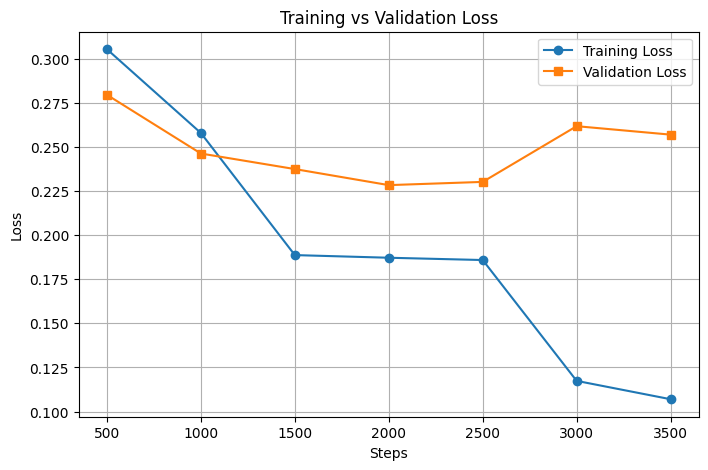

In [ ]:
import matplotlib.pyplot as plt

# Data
steps = [500, 1000, 1500, 2000, 2500, 3000, 3500]
train_loss = [0.305400, 0.257900, 0.188700, 0.187200, 0.185900, 0.117400, 0.107000]
val_loss   = [0.279546, 0.246275, 0.237464, 0.228363, 0.230191, 0.261773, 0.256980]

# Plot
plt.figure(figsize=(8,5))
plt.plot(steps, train_loss, marker='o', label='Training Loss')
plt.plot(steps, val_loss, marker='s', label='Validation Loss')
plt.xlabel("Steps")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
!pip install streamlit
!pip install plotly

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 76.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 84.0 MB/s eta 0:00:00


In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import plotly.express as px

st.set_page_config(page_title="Response Report", layout="wide")

st.title("📊 Response Analysis Report")

st.sidebar.header("Upload Data")
uploaded_file = st.sidebar.file_uploader("Upload a CSV file", type=["csv"])

if uploaded_file is not None:
    df = pd.read_csv(uploaded_file)
    summary = df["response_type"].value_counts(normalize=True) * 100
    summary_df = pd.DataFrame({"Response": summary.index, "Percentage": summary.values})

    st.subheader("Overall Positive vs Negative")
    fig1 = px.bar(
        summary_df,
        x="Percentage",
        y="Response",
        orientation="h",
        color="Response",
        text="Percentage",
        color_discrete_map={"Positive": "green", "Negative": "red"},
    )
    fig1.update_traces(texttemplate="%{text:.1f}%", textposition="outside")
    st.plotly_chart(fig1, use_container_width=True)

    negative_df = df[df["response_type"] == "Negative"]
    if not negative_df.empty:
        neg_summary = negative_df["category"].value_counts(normalize=True) * 100
        neg_df = pd.DataFrame({"Category": neg_summary.index, "Percentage": neg_summary.values})

        st.subheader("Breakdown of Negative Categories")
        fig2 = px.bar(
            neg_df,
            x="Percentage",
            y="Category",
            orientation="h",
            color="Category",
            text="Percentage",
        )
        fig2.update_traces(texttemplate="%{text:.1f}%", textposition="outside")
        st.plotly_chart(fig2, use_container_width=True)
    else:
        st.info("No negative responses found in the dataset.")
else:
    st.info("Please upload a CSV file to generate the report.")


Writing app.py


In [ ]:
!pip install pyngrok


In [ ]:
!pip install stlite


ERROR: Could not find a version that satisfies the requirement stlite (from versions: none)
ERROR: No matching distribution found for stlite


In [ ]:
!npm install -g localtunnel


⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸
added 22 packages in 4s
⠸
⠸3 packages are looking for funding
⠸  run `npm fund` for details
⠸

In [ ]:
get_ipython().system_raw("streamlit run app.py &")
!lt --port 8501


your url is: https://chilly-bananas-attack.loca.lt
^C


In [ ]:
from pyngrok import ngrok

# Start Streamlit in background
get_ipython().system_raw("streamlit run app.py &")

# Open a public URL
public_url = ngrok.connect(port='8501')
public_url


ERROR:pyngrok.process.ngrok:t=2025-09-24T17:49:16+0000 lvl=eror msg="failed to reconnect session" obj=tunnels.session err="authentication failed: Usage of ngrok requires a verified account and authtoken.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nInstall your authtoken: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n"
ERROR:pyngrok.process.ngrok:t=2025-09-24T17:49:16+0000 lvl=eror msg="session closing" obj=tunnels.session err="authentication failed: Usage of ngrok requires a verified account and authtoken.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nInstall your authtoken: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n"
ERROR:pyngrok.process.ngrok:t=2025-09-24T17:49:16+0000 lvl=eror msg="terminating with error" obj=app err="authentication failed: Usage of ngrok requires a verified account and authtoken.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nInstall your aut

PyngrokNgrokError: The ngrok process errored on start: authentication failed: Usage of ngrok requires a verified account and authtoken.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nInstall your authtoken: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n.